In [4]:
# Inspect the date-preserving dataset

df_dates = pd.read_csv(
    "../data/SriLanka_Weather_25000.csv"
)

print("Columns:")
print(df_dates.columns.tolist())

display(df_dates.head())

Columns:
['latitude', 'longitude', 'elevation', 'weathercode', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'apparent_temperature_min', 'apparent_temperature_mean', 'shortwave_radiation_sum', 'rain_sum', 'precipitation_hours', 'windspeed_10m_max', 'windgusts_10m_max', 'winddirection_10m_dominant', 'et0_fao_evapotranspiration', 'month_sin', 'month_cos', 'city_Athurugiriya', 'city_Badulla', 'city_Bentota', 'city_Colombo', 'city_Galle', 'city_Gampaha', 'city_Hambantota', 'city_Hatton', 'city_Jaffna', 'city_Kalmunai', 'city_Kalutara', 'city_Kandy', 'city_Kesbewa', 'city_Kolonnawa', 'city_Kurunegala', 'city_Mabole', 'city_Maharagama', 'city_Mannar', 'city_Matale', 'city_Matara', 'city_Moratuwa', 'city_Mount Lavinia', 'city_Negombo', 'city_Oruwala', 'city_Pothuhera', 'city_Puttalam', 'city_Ratnapura', 'city_Sri Jayewardenepura Kotte', 'city_Trincomalee', 'city_Weligama', 'rain_tomorrow']


,latitude,longitude,elevation,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,...,city_Mount Lavinia,city_Negombo,city_Oruwala,city_Pothuhera,city_Puttalam,city_Ratnapura,city_Sri Jayewardenepura Kotte,city_Trincomalee,city_Weligama,rain_tomorrow
0,6.900002,79.899994,27.0,2,33.0,23.3,28.5,37.7,27.7,32.9,...,0,0,0,0,0,0,0,0,0,1
1,7.099998,81.100006,652.0,51,25.9,17.5,22.0,29.1,19.0,24.4,...,0,0,0,0,0,0,0,0,0,1
2,6.500000,80.000000,10.0,2,30.5,23.6,27.5,37.3,28.0,32.4,...,0,0,0,0,0,0,0,0,0,1
3,7.000000,79.899994,16.0,2,33.3,23.8,28.9,38.8,28.2,33.2,...,0,0,0,0,0,0,0,0,0,1
4,6.099998,80.200010,15.0,1,31.3,23.9,27.3,37.2,28.1,32.5,...,0,0,0,0,0,0,0,0,0,1


In [12]:
# Verify data types and target values

print("Non-numerical columns:")
print(X.select_dtypes(exclude="number").columns.tolist())

print("\nTarget values:")
print(y.unique())

print("\nInfinite values:")
import numpy as np
print(np.isinf(X.to_numpy(dtype=float)).sum())

Non-numerical columns:
[]

Target values:
[1 0]

Infinite values:
0


In [13]:
# Separate input features and target variable

X = df.drop(columns=["rain_tomorrow"])
y = df["rain_tomorrow"]

print("Input features:", X.shape)
print("Target variable:", y.shape)
print("Number of features:", X.shape[1])

Input features: (25000, 49)
Target variable: (25000,)
Number of features: 49


## 3. Data Preparation and Train-Test Split

The dataset contains 25,000 Sri Lankan weather observations.
The target variable is rain_tomorrow, which indicates whether
rainfall will occur the following day.

The dataset has cleaned and encoded.
This section prepares the input features and target variable
for ensemble learning.


In [14]:
# Check rainfall target

print("Target distribution:")
print(df["rain_tomorrow"].value_counts())

print("\nTarget percentages:")
print(
    df["rain_tomorrow"].value_counts(
        normalize=True
    ) * 100
)

Target distribution:
rain_tomorrow
1    17909
0     7091
Name: count, dtype: int64

Target percentages:
rain_tomorrow
1    71.636
0    28.364
Name: proportion, dtype: float64


In [15]:
# Check dataset information

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)

Number of rows: 25000
Number of columns: 50

Column names:
['latitude', 'longitude', 'elevation', 'weathercode', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'apparent_temperature_min', 'apparent_temperature_mean', 'shortwave_radiation_sum', 'rain_sum', 'precipitation_hours', 'windspeed_10m_max', 'windgusts_10m_max', 'winddirection_10m_dominant', 'et0_fao_evapotranspiration', 'month_sin', 'month_cos', 'city_Athurugiriya', 'city_Badulla', 'city_Bentota', 'city_Colombo', 'city_Galle', 'city_Gampaha', 'city_Hambantota', 'city_Hatton', 'city_Jaffna', 'city_Kalmunai', 'city_Kalutara', 'city_Kandy', 'city_Kesbewa', 'city_Kolonnawa', 'city_Kurunegala', 'city_Mabole', 'city_Maharagama', 'city_Mannar', 'city_Matale', 'city_Matara', 'city_Moratuwa', 'city_Mount Lavinia', 'city_Negombo', 'city_Oruwala', 'city_Pothuhera', 'city_Puttalam', 'city_Ratnapura', 'city_Sri Jayewardenepura Kotte', 'city_Trincomalee', 'city_Weligama', 'rain_tomorrow']

Miss

latitude                          float64
longitude                         float64
elevation                         float64
weathercode                         int64
temperature_2m_max                float64
temperature_2m_min                float64
temperature_2m_mean               float64
apparent_temperature_max          float64
apparent_temperature_min          float64
apparent_temperature_mean         float64
shortwave_radiation_sum           float64
rain_sum                          float64
precipitation_hours               float64
windspeed_10m_max                 float64
windgusts_10m_max                 float64
winddirection_10m_dominant          int64
et0_fao_evapotranspiration        float64
month_sin                         float64
month_cos                         float64
city_Athurugiriya                   int64
city_Badulla                        int64
city_Bentota                        int64
city_Colombo                        int64
city_Galle                        

In [5]:
import pandas as pd

df = pd.read_csv("../data/SriLanka_Weather_25000.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())

Dataset shape: (25000, 50)
Missing values: 0


,latitude,longitude,elevation,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,...,city_Mount Lavinia,city_Negombo,city_Oruwala,city_Pothuhera,city_Puttalam,city_Ratnapura,city_Sri Jayewardenepura Kotte,city_Trincomalee,city_Weligama,rain_tomorrow
0,6.900002,79.899994,27.0,2,33.0,23.3,28.5,37.7,27.7,32.9,...,0,0,0,0,0,0,0,0,0,1
1,7.099998,81.100006,652.0,51,25.9,17.5,22.0,29.1,19.0,24.4,...,0,0,0,0,0,0,0,0,0,1
2,6.500000,80.000000,10.0,2,30.5,23.6,27.5,37.3,28.0,32.4,...,0,0,0,0,0,0,0,0,0,1
3,7.000000,79.899994,16.0,2,33.3,23.8,28.9,38.8,28.2,33.2,...,0,0,0,0,0,0,0,0,0,1
4,6.099998,80.200010,15.0,1,31.3,23.9,27.3,37.2,28.1,32.5,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
import pandas as pd
import numpy as np
import sklearn
import xgboost

print("ML environment is ready!")

ML environment is ready!


## 4. Data Preparation and Train-Test Split

In this section, we prepare the 25,000 Sri Lankan weather
observations for rainfall prediction using ensemble learning.

The target variable is `rain_tomorrow`:

- 0 = No rainfall tomorrow
- 1 = Rainfall tomorrow

We separate the input features and target variable before
preparing the training and testing datasets.


In [3]:
# Separate input features and target variable

X = df.drop(columns=["rain_tomorrow"])
y = df["rain_tomorrow"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Number of input features:", X.shape[1])

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (25000, 49)
Target shape: (25000,)
Number of input features: 49

Target distribution:
rain_tomorrow
1    17909
0     7091
Name: count, dtype: int64


## 5. Training and Testing Data Preparation

The dataset is divided chronologically into training and testing
sets to evaluate how the models perform on future weather observations.

Approximately 80% of the records are used for training and
20% for testing. A one-day gap is maintained at the boundary
to avoid using the first test day's rainfall as a training label.

All ensemble learning models will use the same split for
a fair performance comparison.


In [6]:
# Chronological train-test split

import pandas as pd
from datetime import timedelta

# Load the date-preserving dataset
df_dates = pd.read_csv(
    "../data/SriLanka_Weather_Recent_25000.csv"
)

df_dates["time"] = pd.to_datetime(df_dates["time"])

# Confirm both datasets match
assert len(df_dates) == len(df), "Dataset sizes do not match!"
assert (
    df_dates["rain_tomorrow"].to_numpy()
    == df["rain_tomorrow"].to_numpy()
).all(), "Target labels do not match!"

assert (
    df_dates[["latitude", "longitude"]].to_numpy()
    == df[["latitude", "longitude"]].to_numpy()
).all(), "Dataset row order does not match!"

# Find chronological split date
unique_dates = sorted(df_dates["time"].unique())
split_date = pd.Timestamp(
    unique_dates[int(len(unique_dates) * 0.8)]
)

# Keep a one-day gap before the test period
train_mask = df_dates["time"] < split_date - timedelta(days=1)
test_mask = df_dates["time"] >= split_date

# Prepare training and testing sets
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(df_dates.loc[train_mask, "time"].min().date())
print(df_dates.loc[train_mask, "time"].max().date())

print("\nTesting period:")
print(df_dates.loc[test_mask, "time"].min().date())
print(df_dates.loc[test_mask, "time"].max().date())

Training records: 19960
Testing records: 5010

Training period:
2021-03-05
2022-12-30

Testing period:
2023-01-01
2023-06-16


In [7]:
# Verify training and testing data

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

print("\nMissing values in training:",
      X_train.isnull().sum().sum())

print("Missing values in testing:",
      X_test.isnull().sum().sum())

X_train: (19960, 49)
X_test: (5010, 49)
y_train: (19960,)
y_test: (5010,)

Training target distribution:
rain_tomorrow
1    73.572144
0    26.427856
Name: proportion, dtype: float64

Testing target distribution:
rain_tomorrow
1    64.351297
0    35.648703
Name: proportion, dtype: float64

Missing values in training: 0
Missing values in testing: 0


## 6. Decision Tree Classifier — Baseline Model

A Decision Tree is used as the baseline model for rainfall
prediction. It learns decision rules from weather features
to classify whether rainfall will occur the following day.

The baseline model allows us to evaluate whether Bagging,
Boosting and Stacking improve predictive performance.

The model is trained using historical observations and
evaluated on the chronological testing dataset.


In [8]:
# Import Decision Tree and evaluation libraries

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import time

In [9]:
# Create Decision Tree model

dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
start_time = time.time()

dt_model.fit(X_train, y_train)

dt_training_time = time.time() - start_time

print("Decision Tree training completed!")
print(f"Training time: {dt_training_time:.2f} seconds")

Decision Tree training completed!
Training time: 1.56 seconds


In [10]:
# Make predictions

dt_predictions = dt_model.predict(X_test)

# Get predicted probabilities
dt_probabilities = dt_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(
    y_test, dt_predictions, zero_division=0
)
dt_recall = recall_score(
    y_test, dt_predictions, zero_division=0
)
dt_f1 = f1_score(
    y_test, dt_predictions, zero_division=0
)
dt_auc = roc_auc_score(y_test, dt_probabilities)

# Display results
print("Decision Tree Performance")
print("-------------------------")

print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1-score:  {dt_f1:.4f}")
print(f"ROC-AUC:   {dt_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=["No Rain", "Rain"],
    zero_division=0
))

Decision Tree Performance
-------------------------
Accuracy:  0.7671
Precision: 0.8112
Recall:    0.8316
F1-score:  0.8213
ROC-AUC:   0.7957

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.68      0.65      0.67      1786
        Rain       0.81      0.83      0.82      3224

    accuracy                           0.77      5010
   macro avg       0.75      0.74      0.74      5010
weighted avg       0.76      0.77      0.77      5010



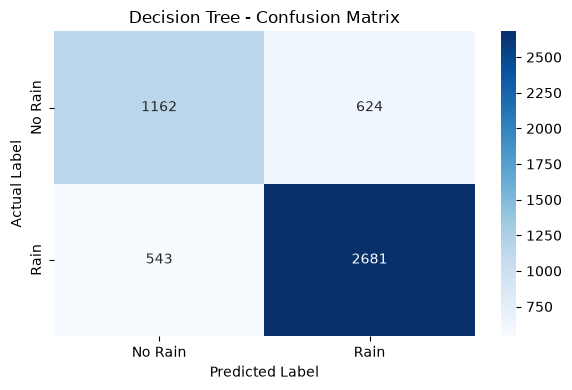

In [11]:
# Plot the confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

dt_cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [12]:
# Store model performance for future comparison

model_results = []

model_results.append({
    "Model": "Decision Tree",
    "Technique": "Baseline",
    "Accuracy": dt_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1-score": dt_f1,
    "ROC-AUC": dt_auc,
    "Training Time (s)": dt_training_time
})

import pandas as pd

results_df = pd.DataFrame(model_results)

display(results_df)

,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603


## 7. Bagging and Random Forest

Bagging is an ensemble learning technique that trains multiple
models independently using different samples of the dataset.

Random Forest extends the bagging approach by introducing
random feature selection during tree construction.

In this section, Bagging Classifier and Random Forest are
implemented and compared with the Decision Tree baseline.


In [13]:
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier
)

In [14]:
# Train Bagging Classifier

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ),
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

bagging_model.fit(X_train, y_train)

bagging_training_time = time.time() - start_time

print("Bagging Classifier trained successfully!")
print(f"Training time: {bagging_training_time:.2f} seconds")

Bagging Classifier trained successfully!
Training time: 39.11 seconds


In [15]:
# Evaluate Bagging Classifier

bagging_predictions = bagging_model.predict(X_test)
bagging_probabilities = bagging_model.predict_proba(X_test)[:, 1]

bagging_accuracy = accuracy_score(y_test, bagging_predictions)
bagging_precision = precision_score(
    y_test, bagging_predictions, zero_division=0
)
bagging_recall = recall_score(
    y_test, bagging_predictions, zero_division=0
)
bagging_f1 = f1_score(
    y_test, bagging_predictions, zero_division=0
)
bagging_auc = roc_auc_score(y_test, bagging_probabilities)

print("Bagging Classifier Results")
print("--------------------------")
print(f"Accuracy: {bagging_accuracy:.4f}")
print(f"Precision: {bagging_precision:.4f}")
print(f"Recall: {bagging_recall:.4f}")
print(f"F1-score: {bagging_f1:.4f}")
print(f"ROC-AUC: {bagging_auc:.4f}")

model_results.append({
    "Model": "Bagging Classifier",
    "Technique": "Bagging",
    "Accuracy": bagging_accuracy,
    "Precision": bagging_precision,
    "Recall": bagging_recall,
    "F1-score": bagging_f1,
    "ROC-AUC": bagging_auc,
    "Training Time (s)": bagging_training_time
})

display(pd.DataFrame(model_results))

Bagging Classifier Results
--------------------------
Accuracy: 0.8024
Precision: 0.8352
Recall: 0.8632
F1-score: 0.8490
ROC-AUC: 0.8692


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126


In [16]:
# Train Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Random Forest trained successfully!")
print(f"Training time: {rf_training_time:.2f} seconds")

Random Forest trained successfully!
Training time: 1.10 seconds


In [17]:
# Evaluate Random Forest

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(
    y_test, rf_predictions, zero_division=0
)
rf_recall = recall_score(
    y_test, rf_predictions, zero_division=0
)
rf_f1 = f1_score(
    y_test, rf_predictions, zero_division=0
)
rf_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy: {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall: {rf_recall:.4f}")
print(f"F1-score: {rf_f1:.4f}")
print(f"ROC-AUC: {rf_auc:.4f}")

model_results.append({
    "Model": "Random Forest",
    "Technique": "Bagging",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-score": rf_f1,
    "ROC-AUC": rf_auc,
    "Training Time (s)": rf_training_time
})

results_df = pd.DataFrame(model_results)
display(results_df)

Random Forest Results
---------------------
Accuracy: 0.8024
Precision: 0.8317
Recall: 0.8688
F1-score: 0.8498
ROC-AUC: 0.8796


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126
2,Random Forest,Bagging,0.802395,0.831651,0.868797,0.849818,0.879561,1.103211


## 8. Boosting — AdaBoost and XGBoost

Boosting is an ensemble learning technique that builds
models sequentially. Each new model attempts to improve
the predictions of the previous ensemble.

In this section, two boosting algorithms are implemented:

- AdaBoost Classifier
- XGBoost Classifier

Their performance is compared with the Decision Tree,
Bagging Classifier and Random Forest using the same
chronological training and testing datasets.


In [18]:
# Import boosting algorithms

from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier

In [19]:
# Train AdaBoost Classifier

ada_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

start_time = time.time()

ada_model.fit(X_train, y_train)

ada_training_time = time.time() - start_time

print("AdaBoost training completed!")
print(f"Training time: {ada_training_time:.2f} seconds")

AdaBoost training completed!
Training time: 5.25 seconds


In [20]:
# Evaluate AdaBoost

ada_predictions = ada_model.predict(X_test)
ada_probabilities = ada_model.predict_proba(X_test)[:, 1]

ada_accuracy = accuracy_score(y_test, ada_predictions)
ada_precision = precision_score(
    y_test, ada_predictions, zero_division=0
)
ada_recall = recall_score(
    y_test, ada_predictions, zero_division=0
)
ada_f1 = f1_score(
    y_test, ada_predictions, zero_division=0
)
ada_auc = roc_auc_score(y_test, ada_probabilities)

print("AdaBoost Results")
print("----------------")
print(f"Accuracy:  {ada_accuracy:.4f}")
print(f"Precision: {ada_precision:.4f}")
print(f"Recall:    {ada_recall:.4f}")
print(f"F1-score:  {ada_f1:.4f}")
print(f"ROC-AUC:   {ada_auc:.4f}")

# Save results
model_results.append({
    "Model": "AdaBoost",
    "Technique": "Boosting",
    "Accuracy": ada_accuracy,
    "Precision": ada_precision,
    "Recall": ada_recall,
    "F1-score": ada_f1,
    "ROC-AUC": ada_auc,
    "Training Time (s)": ada_training_time
})

display(pd.DataFrame(model_results))

AdaBoost Results
----------------
Accuracy:  0.7950
Precision: 0.8047
Recall:    0.8998
F1-score:  0.8496
ROC-AUC:   0.8767


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126
2,Random Forest,Bagging,0.802395,0.831651,0.868797,0.849818,0.879561,1.103211
3,AdaBoost,Boosting,0.795010,0.804716,0.899814,0.849612,0.876747,5.251146


In [21]:
# Train XGBoost Classifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

print("XGBoost training completed!")
print(f"Training time: {xgb_training_time:.2f} seconds")

XGBoost training completed!
Training time: 1.91 seconds


In [22]:
# Evaluate XGBoost

xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(
    y_test, xgb_predictions, zero_division=0
)
xgb_recall = recall_score(
    y_test, xgb_predictions, zero_division=0
)
xgb_f1 = f1_score(
    y_test, xgb_predictions, zero_division=0
)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

print("XGBoost Results")
print("---------------")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-score:  {xgb_f1:.4f}")
print(f"ROC-AUC:   {xgb_auc:.4f}")

# Save results
model_results.append({
    "Model": "XGBoost",
    "Technique": "Boosting",
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "F1-score": xgb_f1,
    "ROC-AUC": xgb_auc,
    "Training Time (s)": xgb_training_time
})

results_df = pd.DataFrame(model_results)

display(results_df)

XGBoost Results
---------------
Accuracy:  0.8018
Precision: 0.8363
Recall:    0.8604
F1-score:  0.8482
ROC-AUC:   0.8721


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126
2,Random Forest,Bagging,0.802395,0.831651,0.868797,0.849818,0.879561,1.103211
3,AdaBoost,Boosting,0.795010,0.804716,0.899814,0.849612,0.876747,5.251146
4,XGBoost,Boosting,0.801796,0.836298,0.860422,0.848188,0.872126,1.908028


In [23]:
# Compare model performance

results_df = pd.DataFrame(model_results)

comparison = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "Training Time (s)": "{:.2f}"
    })
)

,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
2,Random Forest,Bagging,80.24%,83.17%,86.88%,84.98%,87.96%,1.10
3,AdaBoost,Boosting,79.50%,80.47%,89.98%,84.96%,87.67%,5.25
1,Bagging Classifier,Bagging,80.24%,83.52%,86.32%,84.90%,86.92%,39.11
4,XGBoost,Boosting,80.18%,83.63%,86.04%,84.82%,87.21%,1.91
0,Decision Tree,Baseline,76.71%,81.12%,83.16%,82.13%,79.57%,1.56


## 9. Stacking Ensemble Learning

Stacking combines predictions from multiple machine learning
models using an additional model called a meta-model.

In this experiment:

- Random Forest is the first base model.
- XGBoost is the second base model.
- Logistic Regression is the meta-model.

The meta-model learns how to combine the predictions of
Random Forest and XGBoost.

The Stacking Classifier is evaluated using the same
chronological test dataset as the previous models.


In [24]:
# Import Stacking and Logistic Regression

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

In [25]:
# Create Stacking Classifier

stacking_model = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )),
        ("xgb", XGBClassifier(
            n_estimators=100,
            max_depth=5,
            learning_rate=0.1,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=1000
    ),
    cv=5,
    n_jobs=-1
)

# Train Stacking model
start_time = time.time()

stacking_model.fit(X_train, y_train)

stacking_training_time = time.time() - start_time

print("Stacking Classifier trained successfully!")
print(f"Training time: {stacking_training_time:.2f} seconds")

Stacking Classifier trained successfully!
Training time: 21.53 seconds


In [26]:
# Evaluate Stacking Classifier

stacking_predictions = stacking_model.predict(X_test)
stacking_probabilities = stacking_model.predict_proba(X_test)[:, 1]

stacking_accuracy = accuracy_score(y_test, stacking_predictions)
stacking_precision = precision_score(
    y_test, stacking_predictions, zero_division=0
)
stacking_recall = recall_score(
    y_test, stacking_predictions, zero_division=0
)
stacking_f1 = f1_score(
    y_test, stacking_predictions, zero_division=0
)
stacking_auc = roc_auc_score(
    y_test, stacking_probabilities
)

print("Stacking Classifier Results")
print("---------------------------")

print(f"Accuracy:  {stacking_accuracy:.4f}")
print(f"Precision: {stacking_precision:.4f}")
print(f"Recall:    {stacking_recall:.4f}")
print(f"F1-score:  {stacking_f1:.4f}")
print(f"ROC-AUC:   {stacking_auc:.4f}")

# Store results without creating duplicates on reruns
model_results = [
    result for result in model_results
    if result["Model"] != "Stacking Classifier"
]

model_results.append({
    "Model": "Stacking Classifier",
    "Technique": "Stacking",
    "Accuracy": stacking_accuracy,
    "Precision": stacking_precision,
    "Recall": stacking_recall,
    "F1-score": stacking_f1,
    "ROC-AUC": stacking_auc,
    "Training Time (s)": stacking_training_time
})

display(pd.DataFrame(model_results))

Stacking Classifier Results
---------------------------
Accuracy:  0.8036
Precision: 0.8260
Recall:    0.8803
F1-score:  0.8523
ROC-AUC:   0.8771


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126
2,Random Forest,Bagging,0.802395,0.831651,0.868797,0.849818,0.879561,1.103211
3,AdaBoost,Boosting,0.795010,0.804716,0.899814,0.849612,0.876747,5.251146
4,XGBoost,Boosting,0.801796,0.836298,0.860422,0.848188,0.872126,1.908028
5,Stacking Classifier,Stacking,0.803593,0.825960,0.880273,0.852252,0.877067,21.534644


In [27]:
# Final performance comparison

results_df = pd.DataFrame(model_results)

comparison = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "Training Time (s)": "{:.2f}"
    })
)

,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
5,Stacking Classifier,Stacking,80.36%,82.60%,88.03%,85.23%,87.71%,21.53
2,Random Forest,Bagging,80.24%,83.17%,86.88%,84.98%,87.96%,1.10
3,AdaBoost,Boosting,79.50%,80.47%,89.98%,84.96%,87.67%,5.25
1,Bagging Classifier,Bagging,80.24%,83.52%,86.32%,84.90%,86.92%,39.11
4,XGBoost,Boosting,80.18%,83.63%,86.04%,84.82%,87.21%,1.91
0,Decision Tree,Baseline,76.71%,81.12%,83.16%,82.13%,79.57%,1.56


## 10. Model Performance Visualization

This section visually compares the performance of six
machine learning models across different ensemble approaches.

Accuracy, F1-score, ROC-AUC and training time are analyzed
to identify their relative strengths and limitations.


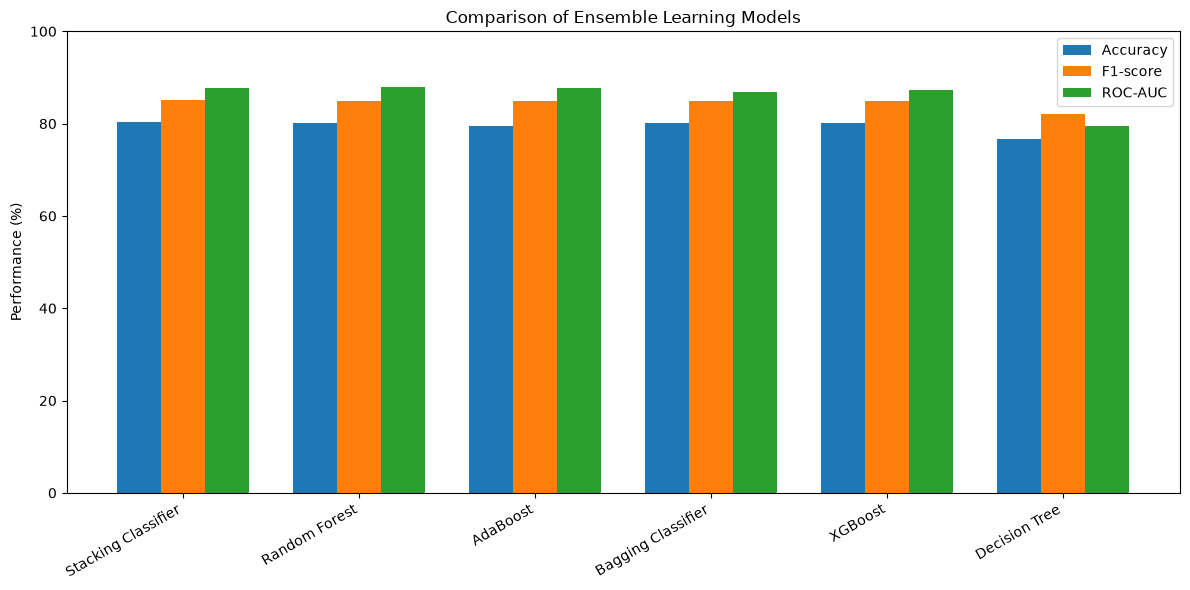

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare results
results_df = pd.DataFrame(model_results)

# Sort by F1-score
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

# Select metrics
metrics = ["Accuracy", "F1-score", "ROC-AUC"]

x = np.arange(len(results_df))
width = 0.25

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1) * width,
        results_df[metric] * 100,
        width,
        label=metric
    )

plt.xticks(
    x,
    results_df["Model"],
    rotation=30,
    ha="right"
)

plt.ylabel("Performance (%)")
plt.title("Comparison of Ensemble Learning Models")
plt.legend()
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

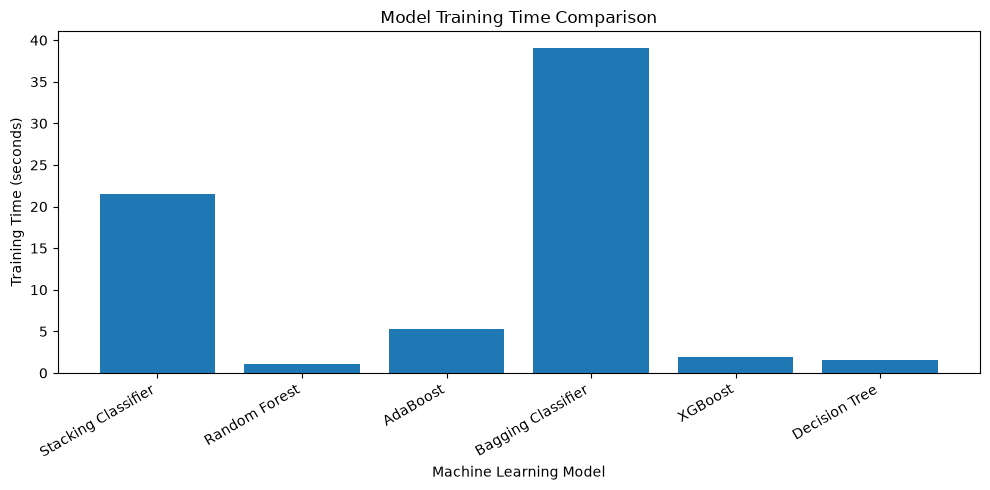

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Training Time (s)"]
)

plt.title("Model Training Time Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Training Time (seconds)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [30]:
best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("Best Model:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.2%}")
print(f"F1-score: {best_model['F1-score']:.2%}")
print(f"ROC-AUC: {best_model['ROC-AUC']:.2%}")

Best Model: Stacking Classifier
Accuracy: 80.36%
F1-score: 85.23%
ROC-AUC: 87.71%


## 11. Results and Discussion

The experimental results show that ensemble learning
methods generally outperform the single Decision Tree
baseline for next-day rainfall classification.

The Stacking Classifier achieved the highest F1-score
(85.23%) and accuracy (80.36%). Combining Random Forest
and XGBoost through a Logistic Regression meta-model
produced a small improvement over the individual models.

Random Forest achieved the highest ROC-AUC (87.96%),
indicating strong discrimination between rainy and
non-rainy observations.

AdaBoost achieved the highest recall (89.98%), making
it effective at identifying actual rainy observations.

Overall, the results demonstrate that model selection
depends on the evaluation metric and the desired balance
between predictive performance and computational cost.


## 12. Saving Trained Models and Evaluation Results

The trained machine learning models are saved for reuse in
the Streamlit dashboard.

Saving the models avoids retraining them whenever the
dashboard is launched.

The evaluation results and feature names are also saved
to support model comparisons and consistent predictions.


In [31]:
# Save trained models

import joblib
from pathlib import Path

# Project models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

trained_models = {
    "decision_tree": dt_model,
    "bagging": bagging_model,
    "random_forest": rf_model,
    "adaboost": ada_model,
    "xgboost": xgb_model,
    "stacking": stacking_model
}

for name, model in trained_models.items():
    file_path = models_dir / f"{name}.joblib"
    joblib.dump(model, file_path)
    print(f"Saved: {file_path.name}")

print("\nAll six models saved successfully!")

Saved: decision_tree.joblib
Saved: bagging.joblib
Saved: random_forest.joblib
Saved: adaboost.joblib
Saved: xgboost.joblib
Saved: stacking.joblib

All six models saved successfully!


In [32]:
# Save model evaluation results

results_df = pd.DataFrame(model_results)

results_path = models_dir / "model_results.csv"

results_df.to_csv(results_path, index=False)

print("Model evaluation results saved!")
display(results_df)

Model evaluation results saved!


,Model,Technique,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Decision Tree,Baseline,0.767066,0.811195,0.831576,0.821259,0.795725,1.563603
1,Bagging Classifier,Bagging,0.802395,0.835234,0.863213,0.848993,0.869187,39.109126
2,Random Forest,Bagging,0.802395,0.831651,0.868797,0.849818,0.879561,1.103211
3,AdaBoost,Boosting,0.795010,0.804716,0.899814,0.849612,0.876747,5.251146
4,XGBoost,Boosting,0.801796,0.836298,0.860422,0.848188,0.872126,1.908028
5,Stacking Classifier,Stacking,0.803593,0.825960,0.880273,0.852252,0.877067,21.534644


In [33]:
# Save feature names

feature_names = X_train.columns.tolist()

joblib.dump(
    feature_names,
    models_dir / "feature_names.joblib"
)

print("Number of features:", len(feature_names))
print("Feature names saved successfully!")

Number of features: 49
Feature names saved successfully!


In [34]:
# Verify saved files

print("Saved model files:\n")

for file in sorted(models_dir.iterdir()):
    print(file.name)

Saved model files:

adaboost.joblib
bagging.joblib
decision_tree.joblib
feature_names.joblib
model_results.csv
random_forest.joblib
stacking.joblib
xgboost.joblib


## AI Assistance Acknowledgment

ChatGPT (OpenAI) was used as a supporting tool during the development of this project. It assisted with understanding ensemble learning concepts, implementing and debugging Python code, evaluating machine learning models, and developing the Streamlit dashboard.

The project uses a Sri Lankan weather dataset to compare Bagging, Boosting, and Stacking techniques. AI-generated suggestions were reviewed and tested during implementation.